In [34]:
# ============================================
# CELL 1 - IMPORT PACKAGES
# ============================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [35]:
# ============================================
# CELL 2 - LOAD JSON
# ============================================

json_path = r"D:\Coop_ephys_exp1\Behavior\D7_lfp_collection\lfp_collection.json" # change path if needed

with open(json_path, "r") as f:
    data = json.load(f)

recording_to_event = data["dictionaries"]["recording_to_event"]

print("Number of recordings:", len(recording_to_event))

Number of recordings: 10


In [36]:
# ============================================
# CELL 3 - EXTRACT ALL EVENTS
# ============================================

def extract_all_events(recording_to_event):

    rows = []

    for recording, events_dict in recording_to_event.items():

        for event_name, intervals in events_dict.items():

            for event_number, interval in enumerate(intervals):

                if len(interval) == 0:
                    continue

                onset = float(interval[0])

                if len(interval) >= 2:
                    offset = float(interval[1])
                    duration = offset - onset
                else:
                    offset = np.nan
                    duration = np.nan

                rows.append({
                    "recording": recording,
                    "event": event_name,
                    "event_number": event_number,
                    "onset": onset,
                    "offset": offset,
                    "duration": duration
                })

    df = pd.DataFrame(rows)

    df = df.sort_values(
        ["recording", "onset", "event"]
    ).reset_index(drop=True)

    df["event_id"] = np.arange(len(df))

    return df


events_df = extract_all_events(recording_to_event)

events_df.head(20)

,recording,event,event_number,onset,offset,duration,event_id
0,20250516_095627_Stage4_D7_1-2_merged.rec,recipient port entry,0,93.95830,94.18795,0.22965,0
1,20250516_095627_Stage4_D7_1-2_merged.rec,recipient port entry,1,94.99795,103.21830,8.22035,1
2,20250516_095627_Stage4_D7_1-2_merged.rec,selfish nose poke,0,100.23850,100.39830,0.15980,2
3,20250516_095627_Stage4_D7_1-2_merged.rec,selfish nose poke,1,101.81805,102.09815,0.28010,3
4,20250516_095627_Stage4_D7_1-2_merged.rec,recipient port entry,2,103.70810,104.82805,1.11995,4
5,20250516_095627_Stage4_D7_1-2_merged.rec,selfish nose poke,2,104.68810,104.86810,0.18000,5
6,20250516_095627_Stage4_D7_1-2_merged.rec,recipient port entry,3,105.02845,105.35810,0.32965,6
7,20250516_095627_Stage4_D7_1-2_merged.rec,selfish nose poke,3,106.43850,106.66835,0.22985,7
8,20250516_095627_Stage4_D7_1-2_merged.rec,selfish nose poke,4,107.73810,107.88850,0.15040,8
9,20250516_095627_Stage4_D7_1-2_merged.rec,recipient port entry,4,109.83825,110.89840,1.06015,9


In [37]:
# ============================================
# CELL 4 - CHECK EVENT TYPES
# ============================================

print("Event types found:\n")

for event in sorted(events_df["event"].unique()):
    print(event)

Event types found:

coop light
coop nose poke
recipient port entry
selfish light
selfish nose poke
subject port entry


In [38]:
# ============================================
# CELL 5 - EVENT COUNTS
# ============================================

event_counts = (
    events_df["event"]
    .value_counts()
    .rename_axis("event")
    .reset_index(name="count")
)

event_counts

,event,count
0,subject port entry,2768
1,recipient port entry,2148
2,selfish light,2054
3,coop light,1223
4,coop nose poke,1139
5,selfish nose poke,889


In [39]:
# ============================================
# CELL 6 - COUNTS BY RECORDING
# ============================================

counts_by_recording = (
    events_df
    .groupby(["recording", "event"])
    .size()
    .unstack(fill_value=0)
)

counts_by_recording

event,coop light,coop nose poke,recipient port entry,selfish light,selfish nose poke,subject port entry
recording,,,,,,
20250516_095627_Stage4_D7_1-2_merged.rec,196,212,223,228,42,312
20250516_095627_Stage4_D7_1-3_merged.rec,196,212,223,228,42,312
20250516_111920_Stage4_D7_2-1_merged.rec,93,2,340,139,1,177
20250516_111920_Stage4_D7_2-4_merged.rec,93,2,340,139,1,177
20250516_135729_Stage4_D7_4-1_merged.rec,115,117,260,212,100,277
20250516_135729_Stage4_D7_4-2_merged.rec,163,187,251,183,21,207
20250516_135729_Stage4_D7_4-3_merged.rec,115,117,260,212,100,277
20250516_135729_Stage4_D7_4-4_merged.rec,163,187,251,183,21,207
20250516_162851_Stage4_D7_6-1_merged.rec,32,37,0,289,269,388


In [40]:
# ============================================
# CELL 7 - ASSIGN CHOICE LABEL
# ============================================

def assign_choice(event_name):

    event_lower = event_name.lower()

    if "coop" in event_lower:
        return "prosocial"

    elif "selfish" in event_lower:
        return "selfish"

    else:
        return "other"


events_df["choice"] = events_df["event"].apply(assign_choice)

events_df.head()

,recording,event,event_number,onset,offset,duration,event_id,choice
0,20250516_095627_Stage4_D7_1-2_merged.rec,recipient port entry,0,93.95830,94.18795,0.22965,0,other
1,20250516_095627_Stage4_D7_1-2_merged.rec,recipient port entry,1,94.99795,103.21830,8.22035,1,other
2,20250516_095627_Stage4_D7_1-2_merged.rec,selfish nose poke,0,100.23850,100.39830,0.15980,2,selfish
3,20250516_095627_Stage4_D7_1-2_merged.rec,selfish nose poke,1,101.81805,102.09815,0.28010,3,selfish
4,20250516_095627_Stage4_D7_1-2_merged.rec,recipient port entry,2,103.70810,104.82805,1.11995,4,other


In [41]:
# ============================================
# CELL 8 - IDENTIFY NOSE-POKES AND LIGHTS
# ============================================

events_df["is_nosepoke"] = events_df["event"].isin([
    "coop nose poke",
    "selfish nose poke"
])

events_df["is_light"] = events_df["event"].isin([
    "coop light",
    "selfish light"
])

In [42]:
# ============================================
# CELL 9 - CALCULATE NOSE-POKE -> LIGHT DELAYS
# ============================================

def calculate_nosepoke_light_delays(
    events_df,
    expected_delay=1.0,
    max_search_delay=3.0
):

    rows = []

    for recording in events_df["recording"].unique():

        rec = events_df[
            events_df["recording"] == recording
        ]

        pairs = [
            ("prosocial", "coop nose poke", "coop light"),
            ("selfish", "selfish nose poke", "selfish light")
        ]

        for choice, nose_name, light_name in pairs:

            nosepokes = rec[
                rec["event"] == nose_name
            ]

            lights = rec[
                rec["event"] == light_name
            ]

            light_times = lights["onset"].values

            for _, nose_row in nosepokes.iterrows():

                nose_time = nose_row["onset"]

                if len(light_times) == 0:
                    continue

                delays = light_times - nose_time

                valid = (
                    (delays > 0) &
                    (delays <= max_search_delay)
                )

                if not np.any(valid):
                    continue

                candidate_delays = delays[valid]

                best_delay = candidate_delays[
                    np.argmin(
                        np.abs(
                            candidate_delays - expected_delay
                        )
                    )
                ]

                rows.append({
                    "recording": recording,
                    "choice": choice,
                    "nosepoke_onset": nose_time,
                    "closest_light_delay": best_delay
                })

    return pd.DataFrame(rows)


delay_df = calculate_nosepoke_light_delays(events_df)

delay_df.head()

,recording,choice,nosepoke_onset,closest_light_delay
0,20250516_095627_Stage4_D7_1-2_merged.rec,prosocial,117.94840,0.99995
1,20250516_095627_Stage4_D7_1-2_merged.rec,prosocial,125.20855,1.00030
2,20250516_095627_Stage4_D7_1-2_merged.rec,prosocial,132.63855,1.00015
3,20250516_095627_Stage4_D7_1-2_merged.rec,prosocial,139.33875,1.00005
4,20250516_095627_Stage4_D7_1-2_merged.rec,prosocial,144.96895,0.99965


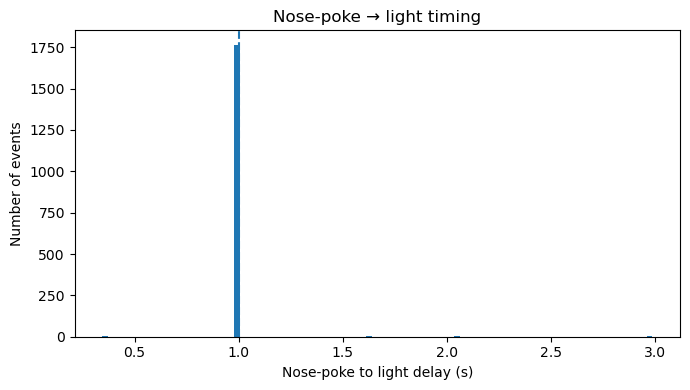

In [43]:
# ============================================
# CELL 10 - PLOT DELAY DISTRIBUTION
# ============================================

plt.figure(figsize=(7, 4))

plt.hist(
    delay_df["closest_light_delay"],
    bins=100
)

plt.axvline(
    1.0,
    linestyle="--"
)

plt.xlabel("Nose-poke to light delay (s)")
plt.ylabel("Number of events")
plt.title("Nose-poke → light timing")

plt.tight_layout()
plt.show()

In [44]:
# ============================================
# CHECK DELAYS SEPARATELY BY CHOICE
# ============================================

for choice in ["prosocial", "selfish"]:

    temp = delay_df[
        delay_df["choice"] == choice
    ]

    print(f"\n{choice.upper()}")
    print(temp["closest_light_delay"].describe())

    print(
        "Within 0.99–1.01 s:",
        (
            (temp["closest_light_delay"] >= 0.99) &
            (temp["closest_light_delay"] <= 1.01)
        ).sum(),
        "/",
        len(temp)
    )


PROSOCIAL
count    1037.000000
mean        1.004996
std         0.063528
min         0.999400
25%         0.999850
50%         1.000000
75%         1.000150
max         2.060000
Name: closest_light_delay, dtype: float64
Within 0.99–1.01 s: 1030 / 1037

SELFISH
count    743.000000
mean       1.013972
std        0.170608
min        0.344500
25%        0.999900
50%        1.000000
75%        1.000150
max        2.990050
Name: closest_light_delay, dtype: float64
Within 0.99–1.01 s: 734 / 743


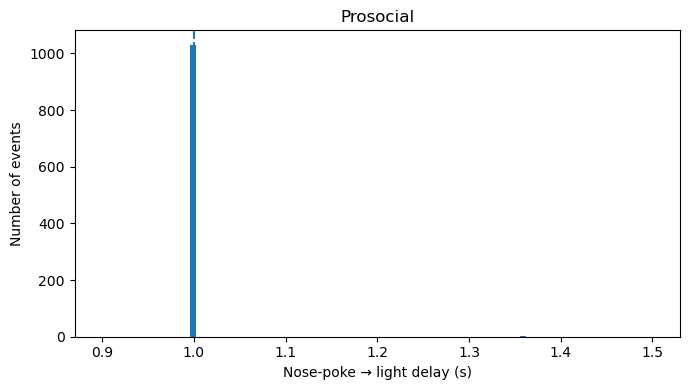

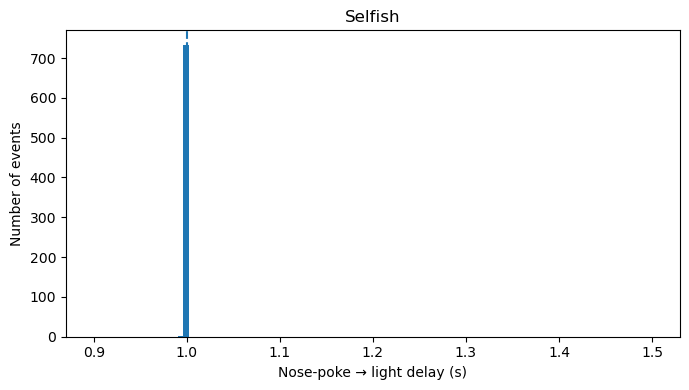

In [45]:
for choice in ["prosocial", "selfish"]:

    temp = delay_df[
        delay_df["choice"] == choice
    ]

    plt.figure(figsize=(7, 4))

    plt.hist(
        temp["closest_light_delay"],
        bins=100,
        range=(0.9, 1.5)
    )

    plt.axvline(
        1.0,
        linestyle="--"
    )

    plt.xlabel("Nose-poke → light delay (s)")
    plt.ylabel("Number of events")
    plt.title(choice.capitalize())

    plt.tight_layout()
    plt.show()

In [46]:
# ============================================
# CELL 11 - CLASSIFY REWARDED NOSE-POKES
# ============================================

def classify_rewarded_nosepokes(
    events_df,
    expected_delay=1.0,
    tolerance=0.10
):

    df = events_df.copy()

    # Columns only relevant to nose-pokes
    df["rewarded"] = pd.Series(
        [np.nan] * len(df),
        dtype="object"
    )

    df["matched_light_onset"] = np.nan
    df["matched_light_offset"] = np.nan
    df["light_delay"] = np.nan
    df["matched_light_event_id"] = np.nan

    for recording in df["recording"].unique():

        pairs = [
            ("coop nose poke", "coop light"),
            ("selfish nose poke", "selfish light")
        ]

        for nose_name, light_name in pairs:

            nose_indices = df[
                (df["recording"] == recording) &
                (df["event"] == nose_name)
            ].index.tolist()

            light_indices = df[
                (df["recording"] == recording) &
                (df["event"] == light_name)
            ].index.tolist()

            # Prevent one light being assigned twice
            available_lights = set(light_indices)

            for nose_idx in nose_indices:

                nose_time = df.loc[
                    nose_idx,
                    "onset"
                ]

                candidates = []

                for light_idx in available_lights:

                    light_onset = df.loc[
                        light_idx,
                        "onset"
                    ]

                    delay = light_onset - nose_time

                    if (
                        expected_delay - tolerance
                        <= delay <=
                        expected_delay + tolerance
                    ):

                        distance_from_expected = abs(
                            delay - expected_delay
                        )

                        candidates.append(
                            (
                                distance_from_expected,
                                light_idx,
                                delay
                            )
                        )

                # ----------------------
                # REWARDED
                # ----------------------
                if len(candidates) > 0:

                    candidates.sort(
                        key=lambda x: x[0]
                    )

                    _, best_light_idx, delay = candidates[0]

                    df.at[
                        nose_idx,
                        "rewarded"
                    ] = True

                    df.at[
                        nose_idx,
                        "matched_light_onset"
                    ] = df.loc[
                        best_light_idx,
                        "onset"
                    ]

                    df.at[
                        nose_idx,
                        "matched_light_offset"
                    ] = df.loc[
                        best_light_idx,
                        "offset"
                    ]

                    df.at[
                        nose_idx,
                        "light_delay"
                    ] = delay

                    df.at[
                        nose_idx,
                        "matched_light_event_id"
                    ] = df.loc[
                        best_light_idx,
                        "event_id"
                    ]

                    available_lights.remove(
                        best_light_idx
                    )

                # ----------------------
                # UNREWARDED
                # ----------------------
                else:

                    df.at[
                        nose_idx,
                        "rewarded"
                    ] = False

    return df

In [47]:
# ============================================
# CELL 12 - RUN CLASSIFICATION
# ============================================

events_classified = classify_rewarded_nosepokes(
    events_df,
    expected_delay=1.0,
    tolerance=0.10
)

events_classified.head(20)

,recording,event,event_number,onset,offset,duration,event_id,choice,is_nosepoke,is_light,rewarded,matched_light_onset,matched_light_offset,light_delay,matched_light_event_id
0,20250516_095627_Stage4_D7_1-2_merged.rec,recipient port entry,0,93.95830,94.18795,0.22965,0,other,False,False,NaN,NaN,NaN,NaN,NaN
1,20250516_095627_Stage4_D7_1-2_merged.rec,recipient port entry,1,94.99795,103.21830,8.22035,1,other,False,False,NaN,NaN,NaN,NaN,NaN
2,20250516_095627_Stage4_D7_1-2_merged.rec,selfish nose poke,0,100.23850,100.39830,0.15980,2,selfish,True,False,False,NaN,NaN,NaN,NaN
3,20250516_095627_Stage4_D7_1-2_merged.rec,selfish nose poke,1,101.81805,102.09815,0.28010,3,selfish,True,False,False,NaN,NaN,NaN,NaN
4,20250516_095627_Stage4_D7_1-2_merged.rec,recipient port entry,2,103.70810,104.82805,1.11995,4,other,False,False,NaN,NaN,NaN,NaN,NaN
5,20250516_095627_Stage4_D7_1-2_merged.rec,selfish nose poke,2,104.68810,104.86810,0.18000,5,selfish,True,False,False,NaN,NaN,NaN,NaN
6,20250516_095627_Stage4_D7_1-2_merged.rec,recipient port entry,3,105.02845,105.35810,0.32965,6,other,False,False,NaN,NaN,NaN,NaN,NaN
7,20250516_095627_Stage4_D7_1-2_merged.rec,selfish nose poke,3,106.43850,106.66835,0.22985,7,selfish,True,False,False,NaN,NaN,NaN,NaN
8,20250516_095627_Stage4_D7_1-2_merged.rec,selfish nose poke,4,107.73810,107.88850,0.15040,8,selfish,True,False,False,NaN,NaN,NaN,NaN
9,20250516_095627_Stage4_D7_1-2_merged.rec,recipient port entry,4,109.83825,110.89840,1.06015,9,other,False,False,NaN,NaN,NaN,NaN,NaN


In [48]:
# ============================================
# CELL 13 - NOSE-POKE TABLE
# ============================================

nosepokes_df = events_classified[
    events_classified["is_nosepoke"]
].copy()

nosepokes_df[
    [
        "recording",
        "event",
        "choice",
        "onset",
        "offset",
        "duration",
        "rewarded",
        "matched_light_onset",
        "matched_light_offset",
        "light_delay"
    ]
].head(50)

,recording,event,choice,onset,offset,duration,rewarded,matched_light_onset,matched_light_offset,light_delay
2,20250516_095627_Stage4_D7_1-2_merged.rec,selfish nose poke,selfish,100.23850,100.39830,0.15980,False,NaN,NaN,NaN
3,20250516_095627_Stage4_D7_1-2_merged.rec,selfish nose poke,selfish,101.81805,102.09815,0.28010,False,NaN,NaN,NaN
5,20250516_095627_Stage4_D7_1-2_merged.rec,selfish nose poke,selfish,104.68810,104.86810,0.18000,False,NaN,NaN,NaN
7,20250516_095627_Stage4_D7_1-2_merged.rec,selfish nose poke,selfish,106.43850,106.66835,0.22985,False,NaN,NaN,NaN
8,20250516_095627_Stage4_D7_1-2_merged.rec,selfish nose poke,selfish,107.73810,107.88850,0.15040,False,NaN,NaN,NaN
10,20250516_095627_Stage4_D7_1-2_merged.rec,selfish nose poke,selfish,112.16820,113.58845,1.42025,False,NaN,NaN,NaN
11,20250516_095627_Stage4_D7_1-2_merged.rec,selfish nose poke,selfish,114.68855,114.87820,0.18965,False,NaN,NaN,NaN
13,20250516_095627_Stage4_D7_1-2_merged.rec,coop nose poke,prosocial,117.94840,118.65825,0.70985,True,118.94835,122.94835,0.99995
18,20250516_095627_Stage4_D7_1-2_merged.rec,coop nose poke,prosocial,125.20855,126.38875,1.18020,True,126.20885,130.20875,1.00030
23,20250516_095627_Stage4_D7_1-2_merged.rec,coop nose poke,prosocial,132.63855,133.37840,0.73985,True,133.63870,137.63850,1.00015


In [49]:
# ============================================
# CELL 14 - SUMMARY
# ============================================

reward_summary = (
    nosepokes_df
    .groupby(
        ["choice", "rewarded"],
        dropna=False
    )
    .size()
    .reset_index(name="n")
)

reward_summary

,choice,rewarded,n
0,prosocial,False,109
1,prosocial,True,1030
2,selfish,False,155
3,selfish,True,734


In [50]:
reward_summary_by_recording = (
    nosepokes_df
    .groupby(
        [
            "recording",
            "choice",
            "rewarded"
        ],
        dropna=False
    )
    .size()
    .reset_index(name="n")
)

reward_summary_by_recording

,recording,choice,rewarded,n
0,20250516_095627_Stage4_D7_1-2_merged.rec,prosocial,False,16
1,20250516_095627_Stage4_D7_1-2_merged.rec,prosocial,True,196
2,20250516_095627_Stage4_D7_1-2_merged.rec,selfish,False,10
3,20250516_095627_Stage4_D7_1-2_merged.rec,selfish,True,32
4,20250516_095627_Stage4_D7_1-3_merged.rec,prosocial,False,16
5,20250516_095627_Stage4_D7_1-3_merged.rec,prosocial,True,196
6,20250516_095627_Stage4_D7_1-3_merged.rec,selfish,False,10
7,20250516_095627_Stage4_D7_1-3_merged.rec,selfish,True,32
8,20250516_111920_Stage4_D7_2-1_merged.rec,prosocial,False,2
9,20250516_111920_Stage4_D7_2-1_merged.rec,selfish,False,1


In [51]:
# ============================================
# CELL 15 - CHECK REWARDED DELAYS
# ============================================

rewarded_nosepokes = nosepokes_df[
    nosepokes_df["rewarded"] == True
]

rewarded_nosepokes[
    "light_delay"
].describe()

count    1764.000000
mean        1.000001
std         0.000307
min         0.990550
25%         0.999850
50%         1.000000
75%         1.000150
max         1.000750
Name: light_delay, dtype: float64

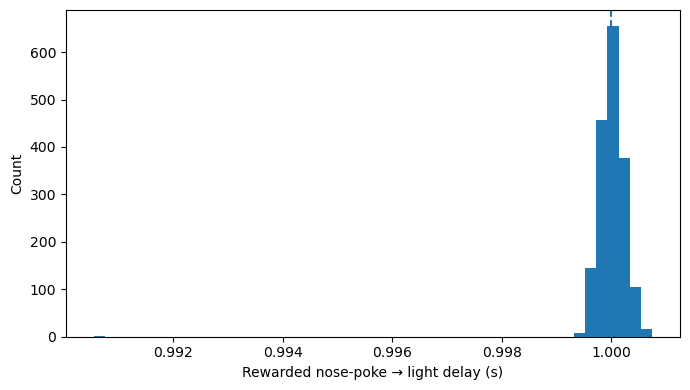

In [52]:
plt.figure(figsize=(7, 4))

plt.hist(
    rewarded_nosepokes["light_delay"],
    bins=50
)

plt.axvline(
    1.0,
    linestyle="--"
)

plt.xlabel("Rewarded nose-poke → light delay (s)")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

In [53]:
# ============================================
# CELL 16 - INSPECT RECORDING
# ============================================

def inspect_recording(
    events_df,
    recording,
    start=None,
    end=None
):

    temp = events_df[
        events_df["recording"] == recording
    ].copy()

    if start is not None:
        temp = temp[
            temp["onset"] >= start
        ]

    if end is not None:
        temp = temp[
            temp["onset"] <= end
        ]

    cols = [
        "event",
        "choice",
        "onset",
        "offset",
        "duration",
        "rewarded",
        "matched_light_onset",
        "matched_light_offset",
        "light_delay"
    ]

    return temp[
        cols
    ].sort_values("onset")

In [54]:
recording = events_classified[
    "recording"
].unique()[0]

inspect_recording(
    events_classified,
    recording,
    start=90,
    end=180
)

,event,choice,onset,offset,duration,rewarded,matched_light_onset,matched_light_offset,light_delay
0,recipient port entry,other,93.95830,94.18795,0.22965,NaN,NaN,NaN,NaN
1,recipient port entry,other,94.99795,103.21830,8.22035,NaN,NaN,NaN,NaN
2,selfish nose poke,selfish,100.23850,100.39830,0.15980,False,NaN,NaN,NaN
3,selfish nose poke,selfish,101.81805,102.09815,0.28010,False,NaN,NaN,NaN
4,recipient port entry,other,103.70810,104.82805,1.11995,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
56,recipient port entry,other,174.13890,180.69935,6.56045,NaN,NaN,NaN,NaN
57,coop nose poke,prosocial,175.92895,176.48905,0.56010,True,176.9291,180.929,1.00015
58,coop light,prosocial,176.92910,180.92900,3.99990,NaN,NaN,NaN,NaN
59,selfish light,selfish,176.92910,180.92900,3.99990,NaN,NaN,NaN,NaN


In [33]:
# ============================================
# CELL 17 - SAVE CSV
# ============================================

from pathlib import Path

output_dir = Path(
    r"C:\Cooperation project\Single_unit_pipeline\Data\Processed"
)

events_classified.to_csv(
    output_dir / "all_behavioral_events_classified_D8.csv",
    index=False
)

print(
    "Saved:",
    output_dir / "all_behavioral_events_classified_D8.csv"
)

Saved: C:\Cooperation project\Single_unit_pipeline\Data\Processed\all_behavioral_events_classified_D8.csv


In [55]:
# ============================================
# CELL 18 - SAVE EXCEL
# ============================================

from pathlib import Path

output_dir = Path(
    r"C:\Cooperation project\Single_unit_pipeline\Data\Processed"
)

rewarded_prosocial = nosepokes_df[
    (nosepokes_df["choice"] == "prosocial") &
    (nosepokes_df["rewarded"] == True)
].copy()

rewarded_selfish = nosepokes_df[
    (nosepokes_df["choice"] == "selfish") &
    (nosepokes_df["rewarded"] == True)
].copy()

unrewarded_prosocial = nosepokes_df[
    (nosepokes_df["choice"] == "prosocial") &
    (nosepokes_df["rewarded"] == False)
].copy()

unrewarded_selfish = nosepokes_df[
    (nosepokes_df["choice"] == "selfish") &
    (nosepokes_df["rewarded"] == False)
].copy()


with pd.ExcelWriter(
    output_dir / "all_behavioral_events_classified_D7.xlsx"
) as writer:

    events_classified.to_excel(
        writer,
        sheet_name="all_events",
        index=False
    )

    nosepokes_df.to_excel(
        writer,
        sheet_name="all_nosepokes",
        index=False
    )

    rewarded_prosocial.to_excel(
        writer,
        sheet_name="rewarded_prosocial",
        index=False
    )

    rewarded_selfish.to_excel(
        writer,
        sheet_name="rewarded_selfish",
        index=False
    )

    unrewarded_prosocial.to_excel(
        writer,
        sheet_name="unrewarded_prosocial",
        index=False
    )

    unrewarded_selfish.to_excel(
        writer,
        sheet_name="unrewarded_selfish",
        index=False
    )

    reward_summary_by_recording.to_excel(
        writer,
        sheet_name="summary",
        index=False
    )


print(
    "Saved:",
    output_dir / "all_behavioral_events_classified_D7.xlsx"
)

Saved: C:\Cooperation project\Single_unit_pipeline\Data\Processed\all_behavioral_events_classified_D7.xlsx
